# Entrenamiento de mini U-Net

In [15]:
# Agregar el directorio raíz del proyecto a las rutas de búsqueda de Python
import sys
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path("..").resolve()

# Agregarlo a las rutas de búsqueda de Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [16]:
# importar bibliotecas necesarias
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.models import MiniUNet
from src.dataset import PetSegmentationDataset
from src.transforms import (
	get_train_transform,
	get_val_transform
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

In [18]:
# Configuración de entrenamiento
TAMANO_IMAGEN = 256
BATCH_SIZE = 4
SPLIT_FILE = "split_70_15_15.csv"
NUM_EPOCHS = 5

In [19]:
# Leer el archivo de configuración
PROYECTO = Path("..")
ruta_config = PROYECTO / "config" / "dataset.json"
with ruta_config.open("r", encoding="utf-8") as archivo:
	config = json.load(archivo)

# Definir rutas de archivos y directorios
RUTA_MANIFEST = PROYECTO / config["manifest"]["path"]
DIRECTORIO_DATA = PROYECTO / "data"
DIRECTORIO_DATASET = PROYECTO / config["dataset"]["root"]
DIRECTORIO_SPLITS = PROYECTO / config["splits"]["path"]

print("Directorio de imágenes:", DIRECTORIO_DATASET)
print("Directorio de particiones:", DIRECTORIO_SPLITS)

Directorio de imágenes: ../data/raw/oxford-iiit-pet
Directorio de particiones: ../data/splits


In [20]:
# Seleccionar una configuración experimental
splits = pd.read_csv(DIRECTORIO_SPLITS / SPLIT_FILE)

# Separar los registros
train_df = splits[splits["split"] == "train"].reset_index(drop=True)
val_df = splits[splits["split"] == "validation"].reset_index(drop=True)
test_df = splits[splits["split"] == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

display(splits.head())

Train: 5173
Validation: 1108
Test: 1109


,image_id,breed,image_path,mask_path,split
0,japanese_chin_145,japanese_chin,images/japanese_chin_145.jpg,annotations/trimaps/japanese_chin_145.png,train
1,basset_hound_84,basset_hound,images/basset_hound_84.jpg,annotations/trimaps/basset_hound_84.png,train
2,boxer_116,boxer,images/boxer_116.jpg,annotations/trimaps/boxer_116.png,train
3,wheaten_terrier_48,wheaten_terrier,images/wheaten_terrier_48.jpg,annotations/trimaps/wheaten_terrier_48.png,train
4,Sphynx_119,Sphynx,images/Sphynx_119.jpg,annotations/trimaps/Sphynx_119.png,train


In [21]:
# Crear datasets
train_dataset = PetSegmentationDataset(
	train_df, DIRECTORIO_DATASET, transform=get_train_transform(TAMANO_IMAGEN)
)

val_dataset = PetSegmentationDataset(
	val_df, DIRECTORIO_DATASET, transform=get_val_transform(TAMANO_IMAGEN)
)

test_dataset = PetSegmentationDataset(
	test_df, DIRECTORIO_DATASET, transform=get_val_transform(TAMANO_IMAGEN)
)

print("Muestras de entrenamiento:", len(train_dataset))
print("Muestras de validación:", len(val_dataset))
print("Muestras de prueba:", len(test_dataset))

Muestras de entrenamiento: 5173
Muestras de validación: 1108
Muestras de prueba: 1109


In [22]:
# Crear DataLoaders
train_loader = DataLoader(
	train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
	val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
	test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

for nombre, dataset, loader in [
	("Train", train_dataset, train_loader),
	("Validation", val_dataset, val_loader),
	("Test", test_dataset, test_loader)
]:
	print(f"{nombre}: {len(dataset)} muestras, {len(loader)} batches")

Train: 5173 muestras, 1294 batches
Validation: 1108 muestras, 277 batches
Test: 1109 muestras, 278 batches


In [23]:
# Configurar el dispositivo de entrenamiento
DEVICE = torch.device(
	"cuda" if torch.cuda.is_available()
	else "mps" if torch.backends.mps.is_available()
	else "cpu"
)

print("Dispositivo de entrenamiento:", DEVICE)

# Instanciar el modelo
modelo = MiniUNet(in_channels=3, num_classes=1).to(DEVICE)

# Configurar la función de pérdida y el optimizador
criterio = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
	modelo.parameters(),
	lr=1e-3
)

Dispositivo de entrenamiento: mps


In [24]:
data, target = next(iter(train_loader))

print("Imágenes:", data.shape)
print("Máscaras:", target.shape)
print("Valores máscara:", torch.unique(target))

with torch.no_grad():
	logits = modelo(data[:1].to(DEVICE))

print("Salida Mini U-Net:", logits.shape)

Imágenes: torch.Size([4, 3, 256, 256])
Máscaras: torch.Size([4, 1, 256, 256])
Valores máscara: tensor([0., 1.])
Salida Mini U-Net: torch.Size([1, 1, 256, 256])


In [25]:
# Guardar la ruta para guardar los checkpoints
checkpoint_path = Path("outputs") / "checkpoints"
CHECKPOINT_DIR = PROYECTO / checkpoint_path
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
# Registrar la ruta en config
with open(ruta_config, "r", encoding="utf-8") as f:
	config = json.load(f)

config["checkpoints"] = {
	"path": str(checkpoint_path)
}

with open(ruta_config, "w", encoding="utf-8") as f:
	json.dump(config, f, indent=4, ensure_ascii=False)

In [26]:
for epoch in range(NUM_EPOCHS):
	modelo.train()
	perdida_acumulada = 0.0
	for batch_idx, (data, target) in enumerate(train_loader):
		# Mover los datos y el target al dispositivo de entrenamiento
		data = data.to(DEVICE)
		target = target.to(DEVICE).float()  # Asegurarse de que el target sea float para BCEWithLogitsLoss

		# Reiniciar los gradientes del optimizador
		optimizer.zero_grad()

		# Forward pass
		logits = modelo(data)

		# Calcular la pérdida
		loss = criterio(logits, target)

		# Backward pass
		loss.backward()

		# Actualizar los parámetros
		optimizer.step()

		# Acumular la pérdida para el cálculo del promedio
		perdida_acumulada += loss.item() * data.size(0)

	# Calcular la pérdida promedio para el conjunto de entrenamiento
	train_loss = perdida_acumulada / len(train_loader.dataset)

	checkpoint_name = f"miniunet_checkpoint_epoch_{epoch + 1}.pth"
	ruta_checkpoint = CHECKPOINT_DIR / checkpoint_name
	torch.save({
    "epoch": epoch,
    "model_state_dict": modelo.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "loss": loss.item()
	}, ruta_checkpoint)
	print(
		f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
		f"Train Loss: {train_loss:.4f}"
	)

Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


Epoch [1/5] Train Loss: 0.4435


Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


Epoch [2/5] Train Loss: 0.3666


Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


Epoch [3/5] Train Loss: 0.3198


Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


Epoch [4/5] Train Loss: 0.2943


Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


Epoch [5/5] Train Loss: 0.2817


## Cargar checkpoint

In [27]:
# Ruta del checkpoint
ruta_checkpoint = CHECKPOINT_DIR / "miniunet_checkpoint_epoch_5.pth"
# Leer el checkpoint
checkpoint = torch.load(
    ruta_checkpoint,
    map_location=DEVICE,
    weights_only=True
)
# Cargar los pesos del modelo desde el checkpoint
modelo.load_state_dict(checkpoint["model_state_dict"])

# Si se desea continuar el entrenamiento desde el checkpoint, también se puede cargar el estado del optimizador
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

## Validación del modelo

In [28]:
# Validación del modelo
modelo.eval()
with torch.no_grad():
	perdida_acumulada = 0.0
	for data, target in val_loader:
		# Mover los datos y el target al dispositivo de entrenamiento
		data = data.to(DEVICE)
		target = target.to(DEVICE).float()  # Asegurarse de que el target sea float para BCEWithLogitsLoss

		# Forward pass
		logits = modelo(data)

		# Calcular la pérdida
		loss = criterio(logits, target)

		# Acumular la pérdida para el cálculo del promedio
		perdida_acumulada += loss.item() * data.size(0)

	# Calcular la pérdida promedio para el conjunto de validación
	val_loss = perdida_acumulada / len(val_loader.dataset)

	print(f"Validation Loss: {val_loss:.4f}")

Validation Loss: 0.2562


## Verificación visual

In [29]:
# Seleccionar una muestra aleatoria
idx = np.random.randint(len(test_dataset))

imagen, mascara = test_dataset[idx]

# Agregar dimensión del batch: (C,H,W) -> (1,C,H,W)
entrada = imagen.unsqueeze(0).to(DEVICE)

# Activar modo evaluación
modelo.eval()

# Realizar inferencia sin calcular gradientes
with torch.no_grad():

    # Forward pass
    logits = modelo(entrada)

    # Convertir logits en probabilidades
    probabilidades = torch.sigmoid(logits)

    # Aplicar umbral para obtener máscara binaria
    prediccion = (probabilidades >= 0.5).float()

print(f"Índice seleccionado: {idx}")
print(f"Imagen: {imagen.shape}")
print(f"Máscara real: {mascara.shape}")
print(f"Predicción: {prediccion.shape}")


Índice seleccionado: 148
Imagen: torch.Size([3, 256, 256])
Máscara real: torch.Size([1, 256, 256])
Predicción: torch.Size([1, 1, 256, 256])


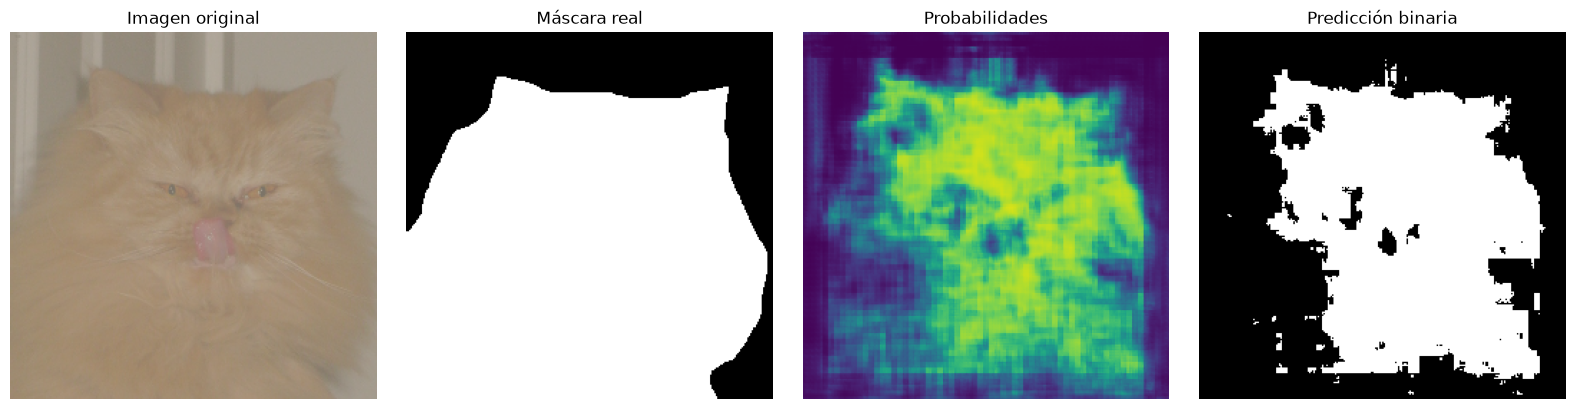

In [30]:
# Recuperar imagen para visualización
imagen_np = imagen.permute(1, 2, 0).cpu().numpy()

# Revertir A.Normalize() con valores predeterminados
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

imagen_np = imagen_np * std + mean
imagen_np = np.clip(imagen_np, 0, 1)

# Preparar máscaras y probabilidades
mascara_np = mascara.squeeze().cpu().numpy()

prob_np = probabilidades[0, 0].cpu().numpy()
pred_np = prediccion[0, 0].cpu().numpy()

# Visualizar
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(imagen_np)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara_np, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara real")

axes[2].imshow(prob_np, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Probabilidades")

axes[3].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Predicción binaria")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
